In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind

In [10]:
df=pd.read_csv("ecommerce_clean_data.csv")

In [11]:
test_df=df[df["orderstatus"]=="Delivered"].copy()

In [12]:
test_df.head()

,orderid,orderdate,customerid,paymentmethod,orderstatus,customername,gender,age,city,region,...,profit,productname,category,costprice,sellingprice,year,month,monthname,yearmonth,profitmarginpct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [14]:
test_df["discountpct"].describe()

count    10970.000000
mean        10.737922
std          7.095532
min          0.000000
25%          5.000000
50%         10.000000
75%         15.000000
max         25.000000
Name: discountpct, dtype: float64

Create two groups

In [15]:
#Step 1 - Order level aggreagation

order_level=(test_df.groupby("orderid")
.agg(
    OrderValue=("salesamount","sum"),
    DiscountPct=("discountpct","mean")
)
.reset_index()
)

In [16]:
order_level.head()

,orderid,OrderValue,DiscountPct
0,O00001,49930.00,10.0
1,O00002,25521.25,7.5
2,O00003,12541.90,5.0
3,O00004,41731.20,15.0
4,O00005,57555.85,15.0


In [17]:
discount_group=order_level[order_level["DiscountPct"]>0]["OrderValue"]

In [18]:
discount_group

0       49930.00
1       25521.25
2       12541.90
3       41731.20
4       57555.85
          ...   
4381    19430.90
4382    12673.50
4383    24658.60
4384    24078.25
4385    21834.00
Name: OrderValue, Length: 4230, dtype: float64

In [19]:
no_discount_group=order_level[order_level["DiscountPct"]==0]["OrderValue"]

In [20]:
no_discount_group

28      33435.0
58      31488.0
161     16574.0
181      4367.0
203      7607.0
         ...   
4200    13202.0
4222    21582.0
4290    12456.0
4303    36372.0
4312     3517.0
Name: OrderValue, Length: 156, dtype: float64

In [21]:
print("Discount Orders: ",len(discount_group))
print("No Discount Orders: ",len(no_discount_group))

Discount Orders:  4230
No Discount Orders:  156


In [23]:
print(
    "Discount AOV: ",
    discount_group.mean()
)

print(
    "Non Discount AOV: ",
    no_discount_group.mean()
)

Discount AOV:  35550.653794326245
Non Discount AOV:  18799.19230769231


In [25]:
print(
    "Discount median: ",
    discount_group.median()
)

print(
    "Non Discount median: ",
    no_discount_group.median()
)

Discount median:  32649.199999999997
Non Discount median:  14292.0


Visual Comparison

In [27]:
comparison_df=pd.DataFrame({
    "AOV": pd.concat(
        [discount_group,no_discount_group],
        ignore_index=True
),
"Group": (
    ["Discount"] * len(discount_group)
    +
    ["No Discount"] * len(no_discount_group)
) 

})

In [29]:
comparison_df

,AOV,Group
0,49930.00,Discount
1,25521.25,Discount
2,12541.90,Discount
3,41731.20,Discount
4,57555.85,Discount
...,...,...
4381,13202.00,No Discount
4382,21582.00,No Discount
4383,12456.00,No Discount
4384,36372.00,No Discount


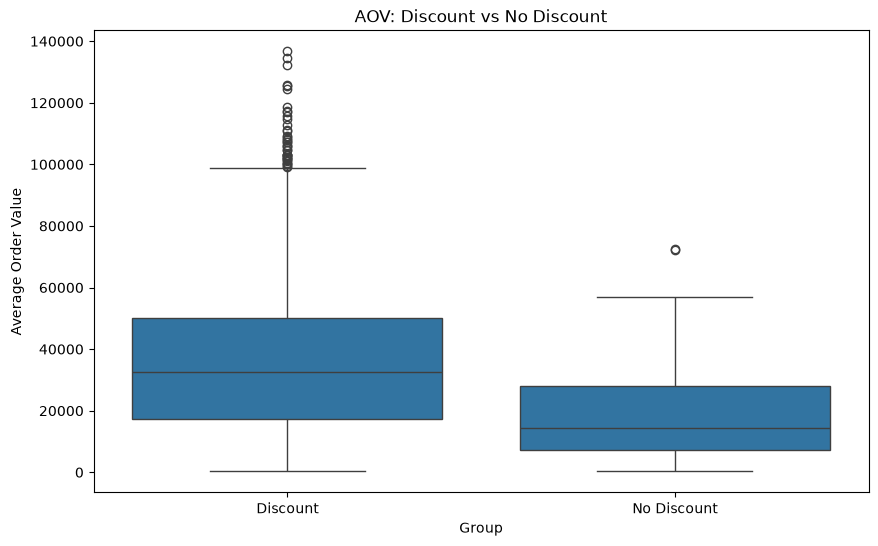

In [31]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=comparison_df,
    x="Group",
    y="AOV"
)

plt.title("AOV: Discount vs No Discount")
plt.xlabel("Group")
plt.ylabel("Average Order Value")

plt.show()

In [33]:
t_stat,p_value=ttest_ind(
    discount_group,
    no_discount_group,
    equal_var=False
)

In [34]:
print("T-Statistic:", t_stat)
print("P-Value:", p_value)

T-Statistic: 13.875792073637808
P-Value: 1.8665022824881592e-30


In [39]:
alpha=0.05

if p_value<alpha:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Reject H0


In [40]:
from scipy.stats import ttest_ind

result = ttest_ind(

discount_group, no_discount_group, equal_var=False )

print(result)

result.confidence_interval()

TtestResult(statistic=np.float64(13.875792073637808), pvalue=np.float64(1.8665022824881592e-30), df=np.float64(184.67236156483705))


ConfidenceInterval(low=np.float64(14369.699004998576), high=np.float64(19133.223968269296))

Effect Difference

In [41]:
aov_difference=(
    discount_group.mean()
    -
    no_discount_group.mean()
)

aov_difference

np.float64(16751.461486633936)

Final Hypothesis Testing Summary

In [46]:

hypothesis_result = pd.DataFrame({

"Metric":[
"Discount AOV",

"No Discount AOV",

"Difference",

"T-Statistic",

"P-Value",

"Alpha"
],
"Value":
[
discount_group.mean(),

no_discount_group.mean(),

aov_difference,

t_stat,

p_value,

alpha]

})

hypothesis_result

,Metric,Value
0,Discount AOV,3.555065e+04
1,No Discount AOV,1.879919e+04
2,Difference,1.675146e+04
3,T-Statistic,1.387579e+01
4,P-Value,1.866502e-30
5,Alpha,5.000000e-02
